# ANA500 Final Project  
## End-to-End Data Science Project: Airline Passenger Satisfaction and Arrival Delay Regression  
**Student:** Scyler Ford  
**Course:** ANA500 - Python for Data Science  

### Project Goal
This final project combines Micro-Projects 1 through 4 into one complete end-to-end data science project. The analysis starts with the original airline passenger dataset, cleans and prepares the data, explores satisfaction and delay patterns, compares traditional machine-learning regression models, adds deep-learning regression, and ends with final recommendations.

## Problem Statement
Airlines collect passenger survey data, service ratings, travel information, and delay information. This project uses that data to describe passenger experience patterns and determine whether arrival delay length can be predicted using flight and passenger-related variables.

## Hypothesis Formulation
This project uses two related hypotheses:

1. Passenger satisfaction is expected to be higher when service ratings such as online boarding, seat comfort, inflight entertainment, and onboard service are higher.
2. Departure Delay in Minutes is expected to be the strongest predictor of Arrival Delay in Minutes. A deep neural network may slightly improve prediction compared with traditional regression, but Linear Regression is expected to remain a strong baseline because departure delay and arrival delay are strongly related.

In [1]:
# Import libraries used throughout the final project.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import LinearSVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make output easier to read.
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)

# Step 1 - Acquire
The final project begins with the original raw airline passenger dataset. Starting from the original file is important because the final project should represent one complete end-to-end workflow rather than beginning with an already-cleaned file.

In [2]:
# Load the original raw airline dataset.
# In GitHub/Jupyter, keep this CSV file in the same folder as the notebook.
raw_df = pd.read_csv('airline_raw.csv')

print('Original dataset shape:', raw_df.shape)
raw_df.head(3)

Original dataset shape: (129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied


In [3]:
# Review column names, data types, and missing values in the raw file.
print(raw_df.columns.tolist())
print('\nTop missing-value counts:')
print(raw_df.isna().sum().sort_values(ascending=False).head(10))

['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Top missing-value counts:
Arrival Delay in Minutes    393
id                            0
Gender                        0
Customer Type                 0
Age                           0
Type of Travel                0
Class                         0
Flight Distance               0
Unnamed: 0                    0
Inflight wifi service         0
dtype: int64


# Step 2 - Prepare
Micro-Project 1 focused on preparing the dataset with Pandas and NumPy. The professor's feedback asked for a clearer review of the missing arrival-delay records. In this final version, those records are identified and compared before they are removed for supervised regression modeling.

In [4]:
# Convert important numeric columns to numeric values.
for col in ['Arrival Delay in Minutes', 'Departure Delay in Minutes', 'Flight Distance', 'Age']:
    raw_df[col] = pd.to_numeric(raw_df[col], errors='coerce')

# Use NumPy to create a missing-target flag for the professor-feedback review.
raw_df['Arrival_Delay_Missing'] = np.where(raw_df['Arrival Delay in Minutes'].isna(), 'Missing', 'Not Missing')

missing_count = int(raw_df['Arrival Delay in Minutes'].isna().sum())
missing_percent = missing_count / len(raw_df) * 100

print('Original records:', len(raw_df))
print('Missing Arrival Delay records:', missing_count)
print('Missing Arrival Delay percent:', round(missing_percent, 2), '%')

Original records: 129880
Missing Arrival Delay records: 393
Missing Arrival Delay percent: 0.3 %


In [5]:
# Investigate whether missing Arrival Delay rows look different from non-missing rows.
missing_review = (
    raw_df.groupby('Arrival_Delay_Missing')
    .agg(
        Records=('Arrival Delay in Minutes', 'size'),
        Mean_Departure_Delay=('Departure Delay in Minutes', 'mean'),
        Median_Departure_Delay=('Departure Delay in Minutes', 'median'),
        Mean_Age=('Age', 'mean'),
        Mean_Flight_Distance=('Flight Distance', 'mean')
    )
    .reset_index()
)

missing_review['order'] = missing_review['Arrival_Delay_Missing'].map({'Missing': 0, 'Not Missing': 1})
missing_review = missing_review.sort_values('order').drop(columns='order')
missing_review.round(2)

,Arrival_Delay_Missing,Records,Mean_Departure_Delay,Median_Departure_Delay,Mean_Age,Mean_Flight_Distance
0,Missing,393,37.89,8.0,39.16,1225.15
1,Not Missing,129487,14.64,0.0,39.43,1190.21


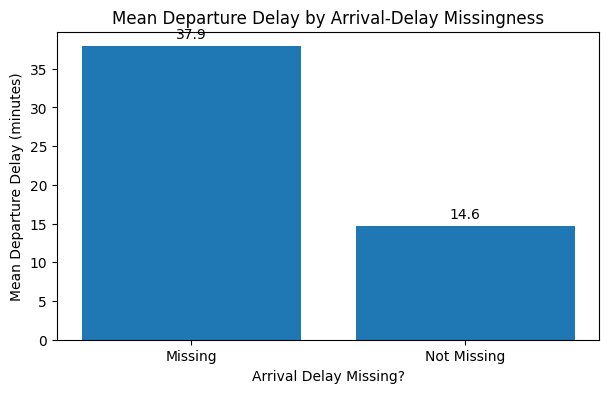

In [6]:
# Visual check: missing-arrival-delay rows have higher average departure delay.
plt.figure(figsize=(7, 4))
plt.bar(missing_review['Arrival_Delay_Missing'], missing_review['Mean_Departure_Delay'])
plt.title('Mean Departure Delay by Arrival-Delay Missingness')
plt.ylabel('Mean Departure Delay (minutes)')
plt.xlabel('Arrival Delay Missing?')
for i, v in enumerate(missing_review['Mean_Departure_Delay']):
    plt.text(i, v + 1, f'{v:.1f}', ha='center')
plt.show()

In [7]:
# Clean the dataset from the original raw file.
# Unnamed: 0 and id are identifiers and are not useful predictors for this project.
df = raw_df.drop(columns=[c for c in ['Unnamed: 0', 'id'] if c in raw_df.columns]).copy()

# Create binary satisfaction field for EDA correlations.
df['satisfaction_binary'] = np.where(df['satisfaction'] == 'satisfied', 1, 0)

# Remove records with missing Arrival Delay because supervised regression requires a known target value.
target = 'Arrival Delay in Minutes'
df_model = df.dropna(subset=[target]).copy()

# Save the cleaned dataset used by the final project.
df_model.to_csv('airline_cleaned_for_final_project.csv', index=False)

print('Cleaned regression records:', len(df_model))
print('Records removed for missing arrival delay:', len(raw_df) - len(df_model))
print('Remaining missing target values:', df_model[target].isna().sum())
print('Cleaned dataset shape:', df_model.shape)

Cleaned regression records: 129487
Records removed for missing arrival delay: 393
Remaining missing target values: 0
Cleaned dataset shape: (129487, 25)


In [8]:
# Descriptive statistics for important numeric fields.
numeric_review = df_model[['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']]
numeric_review.describe().round(2)

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,129487.00,129487.00,129487.00,129487.00
mean,39.43,1190.21,14.64,15.09
std,15.12,997.56,37.93,38.47
min,7.00,31.00,0.00,0.00
25%,27.00,414.00,0.00,0.00
50%,40.00,844.00,0.00,0.00
75%,51.00,1744.00,12.00,13.00
max,85.00,4983.00,1592.00,1584.00


In [9]:
# Arrival-delay outlier review using the IQR rule.
q1 = df_model['Arrival Delay in Minutes'].quantile(0.25)
q3 = df_model['Arrival Delay in Minutes'].quantile(0.75)
iqr = q3 - q1
upper_cutoff = q3 + 1.5 * iqr
outlier_count = int((df_model['Arrival Delay in Minutes'] > upper_cutoff).sum())
outlier_percent = outlier_count / len(df_model) * 100

print('Upper IQR cutoff:', round(upper_cutoff, 2))
print('Arrival-delay outlier records:', outlier_count)
print('Arrival-delay outlier percent:', round(outlier_percent, 1), '%')

Upper IQR cutoff: 32.5
Arrival-delay outlier records: 17492
Arrival-delay outlier percent: 13.5 %


# Step 3 - Analyze Data: Exploratory Data Analysis
Micro-Project 2 focused on visualizations and exploratory analysis. The final project includes satisfaction distribution, satisfaction by class, service correlations, delay distribution, and outlier review.

In [10]:
# Satisfaction distribution.
satisfaction_counts = df_model['satisfaction'].value_counts().rename_axis('satisfaction').reset_index(name='Count')
satisfaction_counts['Percent'] = (satisfaction_counts['Count'] / satisfaction_counts['Count'].sum() * 100).round(1)
satisfaction_counts

,satisfaction,Count,Percent
0,neutral or dissatisfied,73225,56.6
1,satisfied,56262,43.4


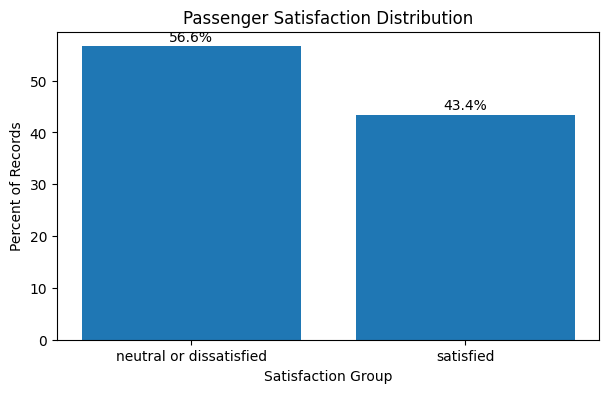

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(satisfaction_counts['satisfaction'], satisfaction_counts['Percent'])
plt.title('Passenger Satisfaction Distribution')
plt.ylabel('Percent of Records')
plt.xlabel('Satisfaction Group')
for i, v in enumerate(satisfaction_counts['Percent']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.show()

In [12]:
# Satisfaction rate by flight class.
class_satisfaction = (df_model.groupby('Class')['satisfaction_binary'].mean() * 100).round(1).reset_index(name='Satisfied Percent')
class_satisfaction = class_satisfaction.sort_values('Satisfied Percent', ascending=False)
class_satisfaction

,Class,Satisfied Percent
0,Business,69.4
2,Eco Plus,24.6
1,Eco,18.8


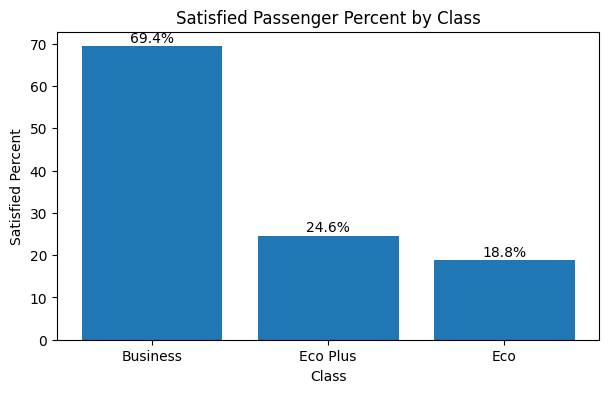

In [13]:
plt.figure(figsize=(7, 4))
plt.bar(class_satisfaction['Class'], class_satisfaction['Satisfied Percent'])
plt.title('Satisfied Passenger Percent by Class')
plt.ylabel('Satisfied Percent')
plt.xlabel('Class')
for i, v in enumerate(class_satisfaction['Satisfied Percent']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.show()

In [14]:
# Correlation between service ratings and satisfaction.
service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Inflight service', 'Cleanliness'
]

service_corr = []
for col in service_cols:
    service_corr.append({
        'Feature': col,
        'Correlation with Satisfaction': df_model[col].corr(df_model['satisfaction_binary'])
    })
service_corr = pd.DataFrame(service_corr).sort_values('Correlation with Satisfaction', ascending=False)
service_corr.round(3).head(6)

,Feature,Correlation with Satisfaction
5,Online boarding,0.502
7,Inflight entertainment,0.398
6,Seat comfort,0.349
8,On-board service,0.322
9,Leg room service,0.313
13,Cleanliness,0.307


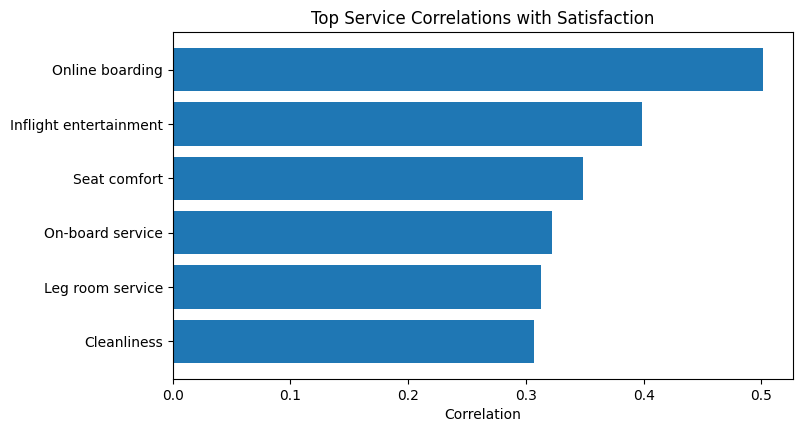

In [15]:
plt.figure(figsize=(8, 4.5))
top_corr = service_corr.head(6).iloc[::-1]
plt.barh(top_corr['Feature'], top_corr['Correlation with Satisfaction'])
plt.title('Top Service Correlations with Satisfaction')
plt.xlabel('Correlation')
plt.show()

In [16]:
# Arrival delay distribution.
delay_groups = pd.cut(
    df_model['Arrival Delay in Minutes'],
    bins=[-0.1, 0, 5, 15, 30, 60, 120, 1e9],
    labels=['0 min', '1-5', '6-15', '16-30', '31-60', '61-120', '120+']
)

delay_distribution = delay_groups.value_counts().sort_index().reset_index()
delay_distribution.columns = ['Delay Range', 'Records']
delay_distribution['Percent'] = (delay_distribution['Records'] / delay_distribution['Records'].sum() * 100).round(1)
delay_distribution

,Delay Range,Records,Percent
0,0 min,72753,56.2
1,1-5,12232,9.4
2,6-15,14944,11.5
3,16-30,11183,8.6
4,31-60,9287,7.2
5,61-120,5896,4.6
6,120+,3192,2.5


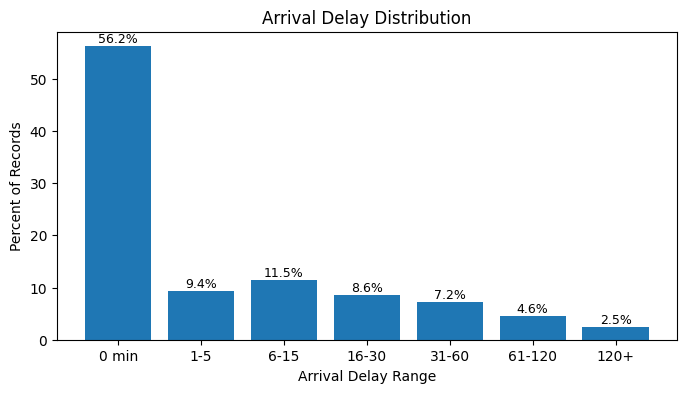

In [17]:
plt.figure(figsize=(8, 4))
plt.bar(delay_distribution['Delay Range'].astype(str), delay_distribution['Percent'])
plt.title('Arrival Delay Distribution')
plt.ylabel('Percent of Records')
plt.xlabel('Arrival Delay Range')
for i, v in enumerate(delay_distribution['Percent']):
    plt.text(i, v + 0.7, f'{v:.1f}%', ha='center', fontsize=9)
plt.show()

# Step 3 - Analyze Data: Regression Modeling
Micro-Project 3 introduced traditional machine-learning regression, and Micro-Project 4 added deep-learning regression. The target variable is `Arrival Delay in Minutes`, which is continuous. The models are evaluated using MAE, RMSE, and R-squared.

In [18]:
# Define predictors and target.
numeric_features = ['Departure Delay in Minutes', 'Flight Distance', 'Age']
categorical_features = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
features = numeric_features + categorical_features

X = df_model[features].copy()
y = df_model[target].astype(float)

# Preprocess numeric and categorical variables.
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# Use one consistent 80/20 split across all regression models.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training records:', len(X_train))
print('Testing records:', len(X_test))

Training records: 103589
Testing records: 25898


In [19]:
# Check simple correlations with arrival delay.
delay_correlations = pd.DataFrame({
    'Feature': ['Departure Delay', 'Flight Distance', 'Age'],
    'Correlation with Arrival Delay': [
        df_model['Departure Delay in Minutes'].corr(df_model[target]),
        df_model['Flight Distance'].corr(df_model[target]),
        df_model['Age'].corr(df_model[target])
    ]
})
delay_correlations.round(3)

,Feature,Correlation with Arrival Delay
0,Departure Delay,0.965
1,Flight Distance,-0.002
2,Age,-0.011


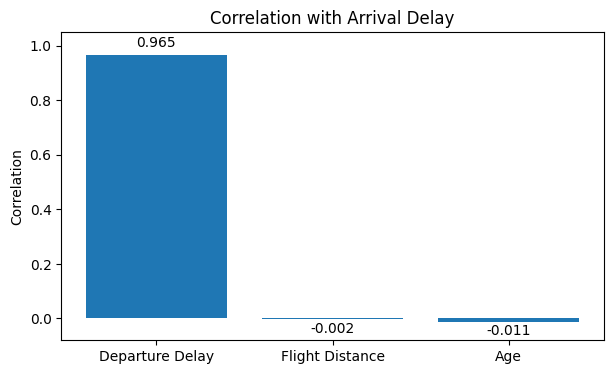

In [20]:
plt.figure(figsize=(7, 4))
plt.bar(delay_correlations['Feature'], delay_correlations['Correlation with Arrival Delay'])
plt.title('Correlation with Arrival Delay')
plt.ylabel('Correlation')
plt.ylim(-0.08, 1.05)
for i, v in enumerate(delay_correlations['Correlation with Arrival Delay']):
    label_y = v + 0.03 if v >= 0 else v - 0.05
    plt.text(i, label_y, f'{v:.3f}', ha='center')
plt.show()

In [21]:
# Helper function for regression model evaluation.
def evaluate_regression_model(model_name, model, X_test, y_test):
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    return {
        'Model': model_name,
        'MAE': round(mae, 3),
        'RMSE': round(rmse, 3),
        'R2': round(r2, 4)
    }, predictions

In [22]:
# Model 1: Multiple Linear Regression.
linear_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_results, linear_predictions = evaluate_regression_model('Multiple Linear Regression', linear_model, X_test, y_test)
linear_results

{'Model': 'Multiple Linear Regression',
 'MAE': 5.341,
 'RMSE': np.float64(9.98),
 'R2': 0.9419}

In [23]:
# Model 2: Linear Support Vector Regression.
svr_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearSVR(C=1.0, epsilon=0.0, max_iter=5000, random_state=42))
])
svr_model.fit(X_train, y_train)
svr_results, svr_predictions = evaluate_regression_model('LinearSVR', svr_model, X_test, y_test)
svr_results

{'Model': 'LinearSVR', 'MAE': 4.926, 'RMSE': np.float64(10.101), 'R2': 0.9405}

In [24]:
# Model 3: Deep Neural Network Regression.
# This is a feed-forward multilayer neural network for tabular regression data.
# The target is scaled because neural networks often train more effectively when target values are scaled.
mlp_base = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=80,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=8,
    random_state=42,
    batch_size=512
)

dnn_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', TransformedTargetRegressor(regressor=mlp_base, transformer=StandardScaler()))
])

dnn_model.fit(X_train, y_train)
dnn_results, dnn_predictions = evaluate_regression_model('Deep Neural Network', dnn_model, X_test, y_test)
dnn_results

{'Model': 'Deep Neural Network',
 'MAE': 5.433,
 'RMSE': np.float64(9.832),
 'R2': 0.9436}

In [25]:
# Compare all models using the same metrics.
model_results = pd.DataFrame([linear_results, svr_results, dnn_results])
model_results

,Model,MAE,RMSE,R2
0,Multiple Linear Regression,5.341,9.980,0.9419
1,LinearSVR,4.926,10.101,0.9405
2,Deep Neural Network,5.433,9.832,0.9436


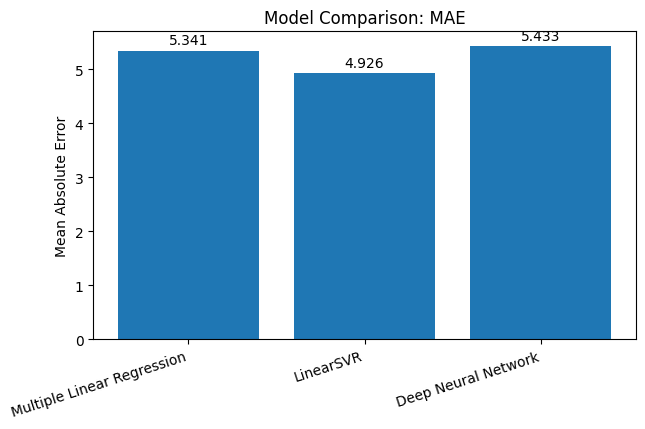

In [26]:
plt.figure(figsize=(7, 4))
plt.bar(model_results['Model'], model_results['MAE'])
plt.title('Model Comparison: MAE')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=18, ha='right')
for i, v in enumerate(model_results['MAE']):
    plt.text(i, v + 0.12, f'{v:.3f}', ha='center')
plt.show()

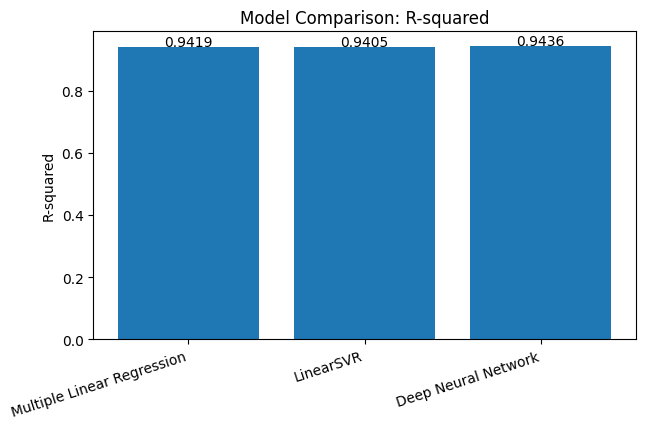

In [27]:
plt.figure(figsize=(7, 4))
plt.bar(model_results['Model'], model_results['R2'])
plt.title('Model Comparison: R-squared')
plt.ylabel('R-squared')
plt.xticks(rotation=18, ha='right')
for i, v in enumerate(model_results['R2']):
    plt.text(i, v + 0.002, f'{v:.4f}', ha='center')
plt.show()

# Step 4 - Report: Severe Delay Performance
The professor's Micro-Project 3 feedback recommended checking whether models perform differently on unusually long delays. The table below evaluates model error by actual delay range instead of only reporting overall averages.

In [28]:
# Evaluate model error by actual delay range.
test_results = pd.DataFrame({
    'Actual': y_test.values,
    'Linear Regression': linear_predictions,
    'LinearSVR': svr_predictions,
    'Deep Neural Network': dnn_predictions
})

test_results['Delay Range'] = pd.cut(
    test_results['Actual'],
    bins=[-0.1, 0, 15, 30, 60, 120, 1e9],
    labels=['0', '1-15', '16-30', '31-60', '61-120', '120+']
)

range_rows = []
for delay_range, sub in test_results.groupby('Delay Range', observed=False):
    range_rows.append({
        'Delay Range': delay_range,
        'Records': len(sub),
        'Mean Actual Delay': round(sub['Actual'].mean(), 2),
        'Linear Regression MAE': round(mean_absolute_error(sub['Actual'], sub['Linear Regression']), 2),
        'LinearSVR MAE': round(mean_absolute_error(sub['Actual'], sub['LinearSVR']), 2),
        'Deep Neural Network MAE': round(mean_absolute_error(sub['Actual'], sub['Deep Neural Network']), 2)
    })

range_performance = pd.DataFrame(range_rows)
range_performance

,Delay Range,Records,Mean Actual Delay,Linear Regression MAE,LinearSVR MAE,Deep Neural Network MAE
0,0,14473,0.00,1.84,1.04,2.37
1,1-15,5448,6.85,6.19,6.19,4.94
2,16-30,2229,22.14,10.70,10.55,10.12
3,31-60,1833,43.17,13.24,13.05,13.94
4,61-120,1239,83.63,15.00,15.05,15.81
5,120+,676,199.18,16.67,18.69,17.44


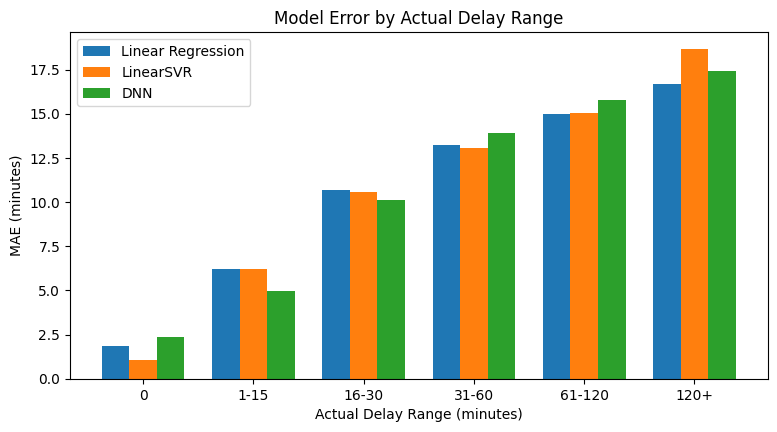

In [29]:
# Visualize severe-delay model performance.
idx = np.arange(len(range_performance))
width = 0.25

plt.figure(figsize=(9, 4.5))
plt.bar(idx - width, range_performance['Linear Regression MAE'], width, label='Linear Regression')
plt.bar(idx, range_performance['LinearSVR MAE'], width, label='LinearSVR')
plt.bar(idx + width, range_performance['Deep Neural Network MAE'], width, label='DNN')
plt.xticks(idx, range_performance['Delay Range'].astype(str))
plt.ylabel('MAE (minutes)')
plt.xlabel('Actual Delay Range (minutes)')
plt.title('Model Error by Actual Delay Range')
plt.legend()
plt.show()

# Step 4 - Report: Departure-Delay Timing
The professor also noted that the strong model results depend heavily on knowing departure delay. This section tests how the deep-learning model performs if `Departure Delay in Minutes` is removed, which represents an earlier prediction scenario.

In [30]:
# Build an early-prediction model without Departure Delay in Minutes.
early_numeric_features = ['Flight Distance', 'Age']
early_features = early_numeric_features + categorical_features

X_early = df_model[early_features].copy()
X_early_train, X_early_test, y_early_train, y_early_test = train_test_split(
    X_early, y, test_size=0.20, random_state=42
)

early_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), early_numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

early_mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=80,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=8,
    random_state=42,
    batch_size=512
)

early_dnn_model = Pipeline([
    ('preprocess', early_preprocessor),
    ('model', TransformedTargetRegressor(regressor=early_mlp, transformer=StandardScaler()))
])

early_dnn_model.fit(X_early_train, y_early_train)
early_result, early_predictions = evaluate_regression_model('DNN without Departure Delay', early_dnn_model, X_early_test, y_early_test)
early_result

{'Model': 'DNN without Departure Delay',
 'MAE': 20.495,
 'RMSE': np.float64(41.413),
 'R2': -0.0006}

In [31]:
# Compare DNN performance with and without departure delay.
timing_comparison = pd.DataFrame([
    dnn_results,
    early_result
])
timing_comparison

,Model,MAE,RMSE,R2
0,Deep Neural Network,5.433,9.832,0.9436
1,DNN without Departure Delay,20.495,41.413,-0.0006


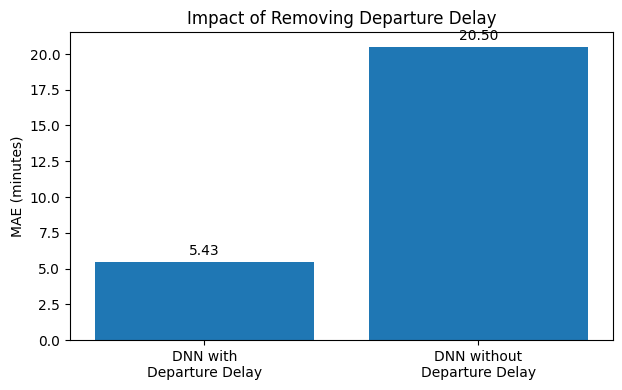

In [32]:
plt.figure(figsize=(7, 4))
plt.bar(['DNN with\nDeparture Delay', 'DNN without\nDeparture Delay'], [dnn_results['MAE'], early_result['MAE']])
plt.title('Impact of Removing Departure Delay')
plt.ylabel('MAE (minutes)')
for i, v in enumerate([dnn_results['MAE'], early_result['MAE']]):
    plt.text(i, v + 0.5, f'{v:.2f}', ha='center')
plt.show()

# Step 4 - Report: Professor Feedback and Grading Criteria Review
This checklist documents how the final project responds to previous feedback and the final grading criteria.

In [33]:
feedback_checklist = pd.DataFrame([
    {'Feedback / Criteria':'Use one complete end-to-end project','How addressed':'Notebook starts from the original 129,880-row dataset and proceeds through cleaning, EDA, ML, deep learning, report, and act.'},
    {'Feedback / Criteria':'Improve problem statement','How addressed':'Problem statement focuses on passenger experience and arrival-delay prediction, not just data cleaning.'},
    {'Feedback / Criteria':'Investigate 393 missing arrival-delay rows','How addressed':'Missing target rows are identified, compared with non-missing records, explained, and then removed for supervised regression.'},
    {'Feedback / Criteria':'Use NumPy and Pandas','How addressed':'Pandas is used for cleaning, grouping, and modeling tables; NumPy is used for flags, binary target creation, and numeric operations.'},
    {'Feedback / Criteria':'Add deeper EDA and visualization','How addressed':'Includes satisfaction distribution, class satisfaction, service correlations, delay distribution, and outlier review.'},
    {'Feedback / Criteria':'Compare consistent regression models','How addressed':'Linear Regression, LinearSVR, and DNN all predict Arrival Delay in Minutes using the same split and metrics.'},
    {'Feedback / Criteria':'Evaluate severe delays','How addressed':'MAE is reported by delay range, including the 120+ minute severe-delay group.'},
    {'Feedback / Criteria':'Discuss departure-delay timing','How addressed':'A second DNN is run without Departure Delay to show early-prediction limitations.'},
    {'Feedback / Criteria':'GitHub repository complete','How addressed':'README, notebook, raw data, cleaned data, presentation, and code PDF are included in the final package.'}
])
feedback_checklist

,Feedback / Criteria,How addressed
0,Use one complete end-to-end project,"Notebook starts from the original 129,880-row ..."
1,Improve problem statement,Problem statement focuses on passenger experie...
2,Investigate 393 missing arrival-delay rows,"Missing target rows are identified, compared w..."
3,Use NumPy and Pandas,"Pandas is used for cleaning, grouping, and mod..."
4,Add deeper EDA and visualization,"Includes satisfaction distribution, class sati..."
5,Compare consistent regression models,"Linear Regression, LinearSVR, and DNN all pred..."
6,Evaluate severe delays,"MAE is reported by delay range, including the ..."
7,Discuss departure-delay timing,A second DNN is run without Departure Delay to...
8,GitHub repository complete,"README, notebook, raw data, cleaned data, pres..."


# Step 5 - Act
The final project supports several practical recommendations:

1. **Use the model after departure-delay information is known.** The models predict arrival delay well when departure delay is included.
2. **Track severe delays separately.** Overall accuracy can hide larger errors for long delays, so severe-delay cases should be monitored on their own.
3. **Use Linear Regression as a strong baseline.** The neural network slightly improves RMSE and R-squared, but Linear Regression is nearly as strong and easier to explain.
4. **Build a better early-warning model if earlier prediction is required.** The early model without departure delay performs poorly, so future work should add weather, airport congestion, aircraft status, crew status, and route-level variables.

In [34]:
print('Final conclusion:')
print('Arrival delay is highly predictable when departure delay is known.')
print('The deep neural network had the best RMSE and R-squared, but the improvement over Linear Regression was small.')
print('Severe delays and early-prediction limitations should be reviewed before operational use.')

Final conclusion:
Arrival delay is highly predictable when departure delay is known.
The deep neural network had the best RMSE and R-squared, but the improvement over Linear Regression was small.
Severe delays and early-prediction limitations should be reviewed before operational use.
